# ERC circularité · 06 · Synthèse pour les décideurs

Ce notebook réunit ce qu'il faut pour décider : les indicateurs, leurs limites, ce qui reste à obtenir, et l'outil qui permet de faire varier les paramètres sans toucher au code. Les notebooks 01 à 05 détaillent comment chaque chiffre est obtenu.

In [1]:
import sys
from pathlib import Path

# Le dossier est celui qui contient le code (erc/) : le parent de notebooks/.
dossier = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erc" / "__init__.py").is_file()), Path.cwd().parent)
sys.path.insert(0, str(dossier))
import erc
from erc import affichage as aff

ctx = erc.executer(jusqua="synthese")

ERC circularité — DÉMONSTRATION (données fictives)


  étape sources       3 artefacts → artefacts/00_sources/


  étape classement   13 artefacts → artefacts/01_classement/


  étape flux         14 artefacts → artefacts/02_flux/


  étape fiabilite    11 artefacts → artefacts/03_fiabilite/


  étape rex          13 artefacts → artefacts/04_rex/


  étape ligne        17 artefacts → artefacts/05_ligne/


  étape synthese      5 artefacts → artefacts/06_synthese/


In [2]:
aff.etat(ctx)

DÉMONSTRATION : toutes les données affichées sont fictives. Période : du 01/06/2026 au 01/11/2026, 154 jours extraits. Aucune anomalie de calcul.

## 1. Tableau de décision

Les indicateurs de la ligne de démontage et de tri, au centre des plages de paramètres et en probabilité. La colonne « Lecture » dit comment chaque valeur est obtenue.

**Lecture** : « inconnu » signifie qu'une donnée d'entrée manque ; l'indicateur n'est pas calculé plutôt que calculé faux. Le gain annuel se lit avec sa fourchette (P5, médiane, P95) et avec le nombre de types de FRU incomplets : plus il y en a, plus le gisement réel est sous-estimé.

**Limite** : en démonstration, ces chiffres sont fictifs.

In [3]:
aff.table(ctx, "synthese", "Tableau de décision")

Indicateur,Valeur,Lecture
Gain annuel par rapport à la situation actuelle,42 361 €,"Total « avec la ligne » moins total « actuel », au centre des plages"
Probabilité que la ligne soit rentable,100 %,400 tirages des plages de paramètres
Résultat annuel : P5 / médiane / P95,24 335 € / 38 295 € / 53 519 €,Monte-Carlo
"Résultat annualisé, semaine par semaine",32 468 €,"Flux hebdomadaire réel, coût fixe payé chaque semaine, pas de stock"
Coût de la variabilité du flux,9 893 €/an,Écart entre le modèle annuel au flux moyen et le calcul semaine par semaine
Seuil de rentabilité,90 FRU/an,Coûts fixes annualisés ÷ marge moyenne par FRU
Retour sur investissement,"0,6 ans",Investissement ÷ (marge variable − coûts fixes annuels)
Heures utilisées / capacité,900 h / 900 h,Au centre des plages
Valeur d'une heure opérateur en plus,50 €,Marge nette qu'apporterait une heure de plus (0 si la capacité n'est pas saturée)
Masse détournée de la benne actuelle,24 665 kg/an,Pièces réemployées ou triées


**Actuel contre ligne.** Le coût annuel de la situation actuelle (tous les FRU rebutés partent chez le recycleur actuel) comparé au bilan avec la ligne, poste par poste puis au total. Lecture : l'écart entre les deux barres du total est le gain annuel attendu de la ligne.

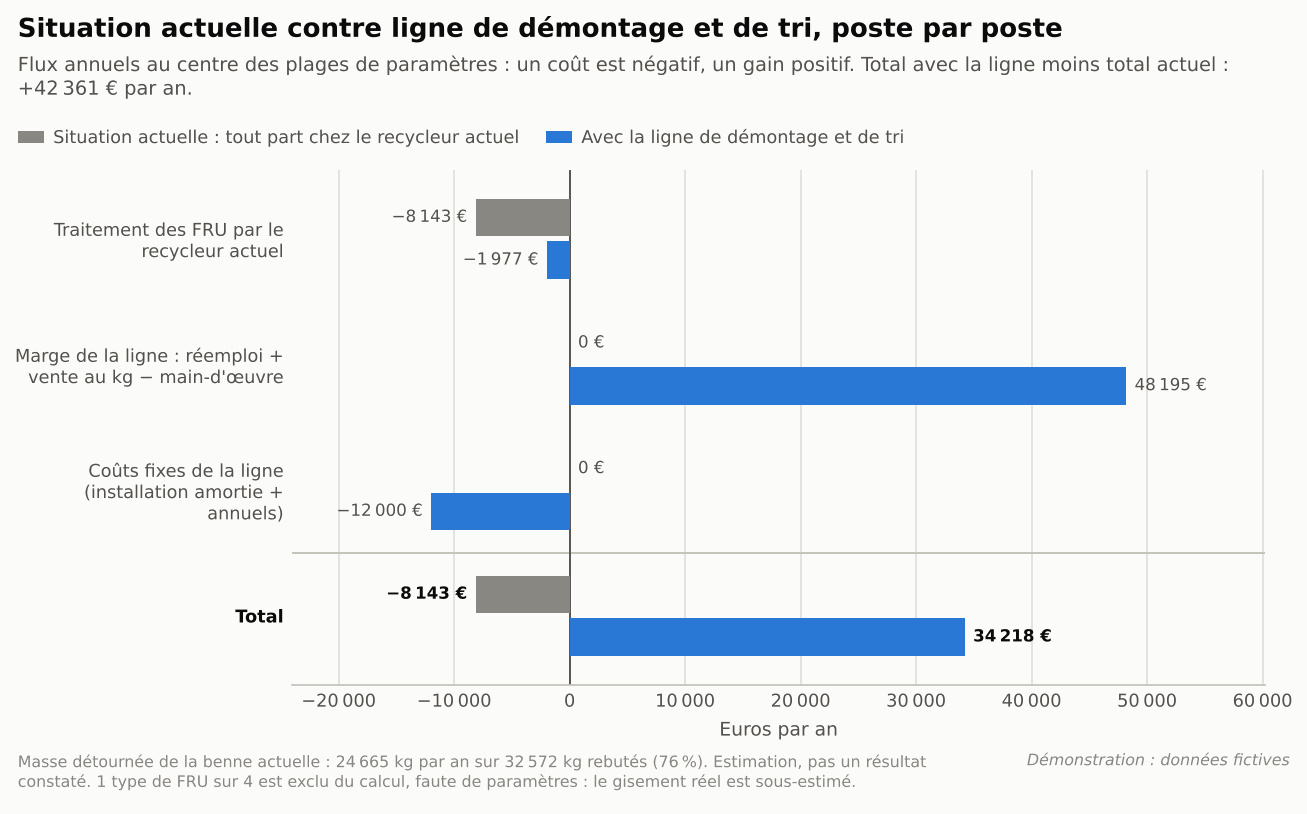

**Monte-Carlo.** Ce que devient le résultat annuel quand tous les paramètres incertains varient dans leurs plages. Lecture : P5 et P95 encadrent neuf tirages sur dix ; la part de la distribution à gauche de zéro est le risque que la ligne ne soit pas rentable.

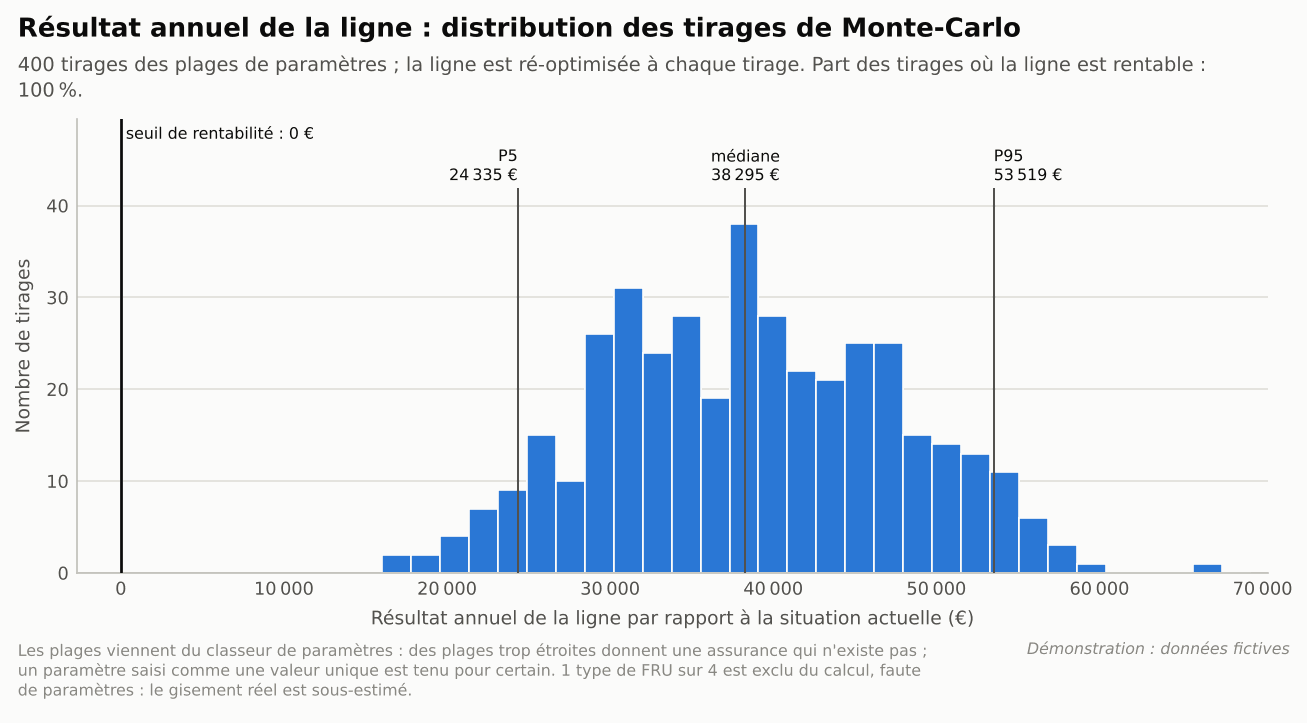

In [4]:
aff.figures(ctx, "ligne", ["Actuel contre ligne", "Monte-Carlo"])

## 2. Limites et lecture

Ce que les données ne permettent pas d'affirmer. À joindre à toute présentation des chiffres ci-dessus.

In [5]:
aff.table(ctx, "synthese", "Limites et lecture")

Élément,À savoir
Mode,DÉMONSTRATION (données fictives)
Période,"du 01/06/2026 au 01/11/2026, 154 jours extraits"
MMICV,"Coût standard : référence provisoire, ni prix de revente ni valeur de réemploi. Devise à confirmer."
Nombre de pièces par FRU,Inconnu sans audit de démontage : le maximum observé sur un PO est un minimum.
Fiabilité,"Le fichier de fiabilité ne contient que des défaillances : il donne la forme et un taux précoce, pas une durée de vie."
Valeurs potentielles,"Estimations, distinctes des recettes réelles. Toute entrée inconnue laisse le résultat vide."
Banc d'essai du modèle de Rex,"Simulation synthétique : démontre la méthode, ne décrit pas l'atelier."


## 3. Données à obtenir

L'état de préparation des paramètres, puis la liste de ce qui manque pour calculer, avec le service à qui le demander. C'est le plan d'action qui améliore le plus la décision : chaque paramètre obtenu fait entrer un type de FRU ou une option dans le calcul.

**Préparation des paramètres.** Où en est la collecte des paramètres du modèle : pour la ligne et pour chaque type de FRU, combien de paramètres sont saisis, tirés des données ou manquants. Lecture : seuls les segments orange empêchent un calcul ; ils désignent les données à obtenir en priorité.

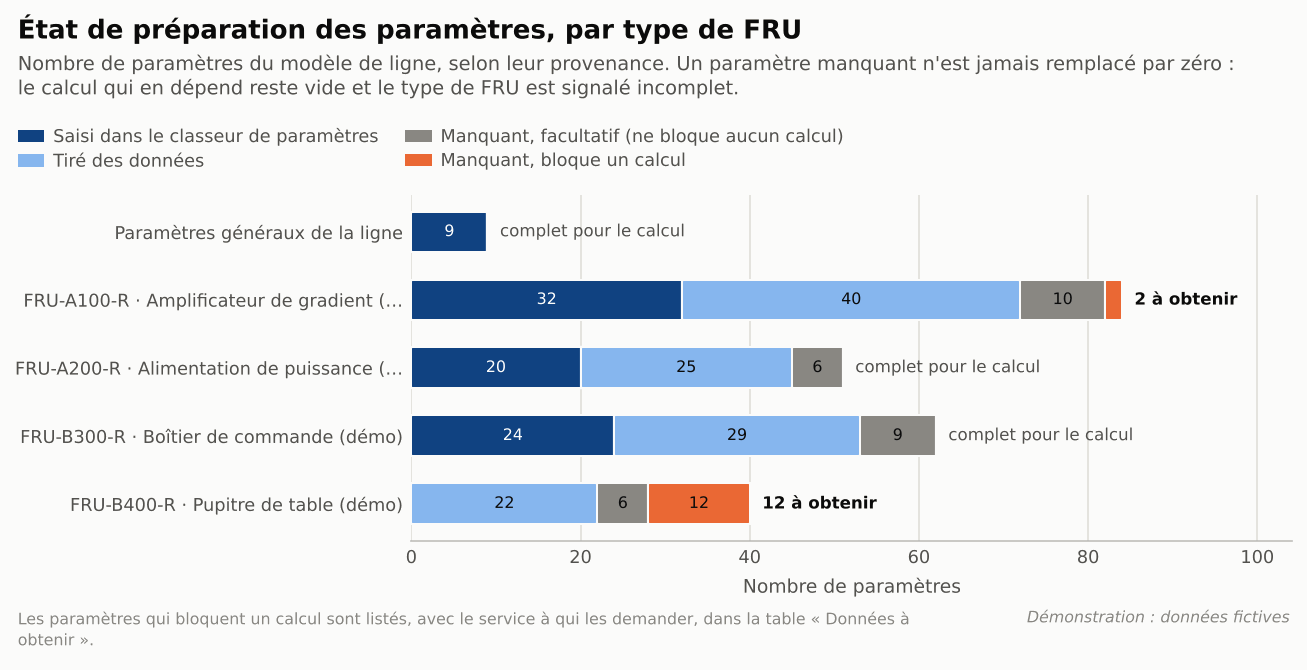

In [6]:
aff.figures(ctx, "synthese", "Préparation des paramètres")

In [7]:
aff.table(ctx, "ligne", "Données à obtenir")

Paramètre,Donnée,Valeurs manquantes,FRU concernés,À demander à
tri_min,Tri d'un exemplaire vers son flux de recyclage (minutes),4,1,Audit de démontage chronométré
test_min,Test d'un exemplaire (minutes),3,1,"Audit de démontage chronométré, qualité"
extraction_min,Extraction d'un exemplaire (minutes),3,1,Audit de démontage chronométré
poids_kg,Poids d'un exemplaire (vide = classement matière),1,1,Pesée
ouverture_min,"Ouverture soignée du FRU, pour extraire des pièces à réemployer (minutes)",1,1,Audit de démontage chronométré
prix_recycleur_eur_kg,Prix payé par le recycleur acheteur (vide = référentiel des grades),1,1,Consultation des recycleurs
valeur_eur,Valeur d'une pièce réemployée (vide = MMICV × fraction de la ligne),1,1,Finance supply chain


## 4. L'outil des décideurs

Une page autonome, qui s'ouvre dans un navigateur sans installation. Elle reprend les paramètres du modèle avec leur provenance et recalcule la ligne quand on les modifie. Elle est produite par l'étape de synthèse à partir des mêmes données que ce notebook.

In [8]:
aff.outil(ctx)

Outil des décideurs : demo/artefacts/outil/ERC_Outil_Decision.html. Page autonome, à ouvrir dans un navigateur (double-clic sur le fichier). [../demo/artefacts/outil/ERC_Outil_Decision.html]

## 5. Anomalies de cette exécution

Table vide = tous les calculs ont abouti. Sinon, traiter l'anomalie avant de présenter les résultats de l'étape concernée.

In [9]:
aff.anomalies(ctx)

Étape,Calcul,Erreur


---
Fin du parcours. Pour mettre à jour les résultats : compléter le classeur de paramètres ou ajouter des extractions, puis relancer les notebooks dans l'ordre (ou seulement **00_Demarrage**, qui exécute tout).